In [1]:
import pandas as pd
import torch
import numpy as np
import random

In [2]:
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler

In [3]:
train_df = pd.read_csv("../data/burgers_train.csv")
test_df = pd.read_csv("../data/burgers_test.csv")

In [6]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset


def prepare_deeponet_data(df, Nx=32, Nt=500):
    """Formats wide DataFrames into structured arrays for DeepONet training."""
    num_samples = len(df)
    total_mesh = Nx * Nt
    vals = df.values

    # Extract raw vectors from dataframe
    x_flat = vals[:, 3 : 3 + total_mesh]
    t_flat = vals[:, 3 + total_mesh : 3 + 2 * total_mesh]
    u_flat = vals[:, 3 + 2 * total_mesh :]

    # Reshape matrices
    x_mesh = x_flat.reshape(num_samples, Nt, Nx)
    t_mesh = t_flat.reshape(num_samples, Nt, Nx)
    u_mesh = u_flat.reshape(num_samples, Nt, Nx)

    # Branch Input: Initial Condition u(x, t=0) -> Shape: [Samples, 1, Nx] for 1D Conv
    u_init = torch.tensor(u_mesh[:, 0, :], dtype=torch.float32).unsqueeze(1)

    # Trunk Input: (x, t) coordinate pairs
    x_coords = torch.tensor(x_mesh[0].flatten(), dtype=torch.float32)
    t_coords = torch.tensor(t_mesh[0].flatten(), dtype=torch.float32)
    coords = torch.stack([x_coords, t_coords], dim=-1)  # Shape: [Nx * Nt, 2]

    targets = torch.tensor(u_mesh.reshape(num_samples, -1), dtype=torch.float32)

    return TensorDataset(u_init, targets), coords



train_dataset, coords = prepare_deeponet_data(train_df, Nx=32, Nt=500)
test_dataset, _ = prepare_deeponet_data(test_df, Nx=32, Nt=500)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [9]:
class ConvBranchNet(nn.Module):
    """1D CNN to process the spatial initial condition profile."""

    def __init__(self, in_channels=1, num_filters=32, output_dim=64):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels, num_filters, kernel_size=5, padding=2),
            nn.Tanh(),
            nn.AvgPool1d(kernel_size=2),
            nn.Conv1d(num_filters, num_filters * 2, kernel_size=5, padding=2),
            nn.Tanh(),
            nn.AvgPool1d(kernel_size=2),
        )
        # Dummy forward to automatically calculate linear input shape dynamically
        self.fc = nn.Linear(num_filters * 2 * (32 // 4), output_dim)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)


class TrunkNet(nn.Module):
    """MLP to process continuous space-time coordinate queries."""

    def __init__(self, in_dim=2, hidden_dim=64, layers=3, output_dim=64):
        super().__init__()
        net = []
        current_dim = in_dim
        for _ in range(layers):
            net.append(nn.Linear(current_dim, hidden_dim))
            net.append(nn.Tanh())
            current_dim = hidden_dim
        net.append(nn.Linear(current_dim, output_dim))
        self.mlp = nn.Sequential(*net)

    def forward(self, x):
        return self.mlp(x)


class ConvDeepONet(nn.Module):
    """Combines Branch and Trunk via a dot product step."""

    def __init__(self, branch_net, trunk_net):
        super().__init__()
        self.branch = branch_net
        self.trunk = trunk_net

    def forward(self, x_branch, x_trunk):
        # x_branch: [Batch, 1, Nx] -> Embedding: [Batch, output_dim]
        b_emb = self.branch(x_branch)
        # x_trunk: [Nx * Nt, 2] -> Embedding: [Nx * Nt, output_dim]
        t_emb = self.trunk(x_trunk)

        # [Batch, output_dim] x [output_dim, Nx * Nt] -> [Batch, Nx * Nt]
        out = torch.matmul(b_emb, t_emb.T)
        return out

In [10]:
PARAM_SPACE_DON = {
    "num_filters": [16, 32, 48],
    "trunk_hidden": [32, 64, 128],
    "trunk_layers": [2, 3, 4],
    "embedding_dim": [32, 64, 96],
    "lr": [1e-3, 2e-3, 5e-3],
    "weight_decay": [1e-6, 1e-4, 0.0],
}


def sample_hyperparameters(space):
    return {k: random.choice(v) for k, v in space.items()}


class RelativeL2Loss(object):

    def __call__(self, y_pred, y_true):
        num_examples = y_pred.size(0)
        diff_norms = torch.norm(
            y_pred.reshape(num_examples, -1) - y_true.reshape(num_examples, -1), 2, 1
        )
        true_norms = torch.norm(y_true.reshape(num_examples, -1), 2, 1)
        return torch.mean(diff_norms / (true_norms + 1e-8))


def train_and_evaluate_don(config, train_loader, test_loader, coords, epochs=10):
    branch = ConvBranchNet(
        num_filters=config["num_filters"], output_dim=config["embedding_dim"]
    )
    trunk = TrunkNet(
        hidden_dim=config["trunk_hidden"],
        layers=config["trunk_layers"],
        output_dim=config["embedding_dim"],
    )
    model = ConvDeepONet(branch, trunk)

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=config["lr"], weight_decay=config["weight_decay"]
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = RelativeL2Loss()

    best_val_loss = float("inf")

    for epoch in range(epochs):
        model.train()
        for X_branch, Y_target in train_loader:
            optimizer.zero_grad()
            output = model(X_branch, coords)
            loss = criterion(output, Y_target)
            loss.backward()
            optimizer.step()
        scheduler.step()

        # Validation
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_branch, Y_target in test_loader:
                output = model(X_branch, coords)
                val_loss += criterion(output, Y_target).item() * X_branch.size(0)

        val_loss /= len(test_loader.dataset)
        if val_loss < best_val_loss:
            best_val_loss = val_loss

    return best_val_loss

In [11]:
NUM_SEARCH_ITERATIONS = 10
EPOCHS_PER_RUN = 10

best_don_loss = float("inf")
best_don_config = None

print("Starting DeepONet Random Search on CPU...")

for trial in range(NUM_SEARCH_ITERATIONS):
    current_config = sample_hyperparameters(PARAM_SPACE_DON)
    print(f"\n--- Trial {trial + 1}/{NUM_SEARCH_ITERATIONS} ---")
    print(f"Testing Config: {current_config}")

    score = train_and_evaluate_don(
        current_config, train_loader, test_loader, coords, epochs=EPOCHS_PER_RUN
    )
    print(f"Trial Best Val Relative L2 Loss: {score:.5f}")

    if score < best_don_loss:
        best_don_loss = score
        best_don_config = current_config
        print(" New overall best DeepONet configuration discovered!")

Starting DeepONet Random Search on CPU...

--- Trial 1/10 ---
Testing Config: {'num_filters': 32, 'trunk_hidden': 128, 'trunk_layers': 3, 'embedding_dim': 32, 'lr': 0.002, 'weight_decay': 0.0}
Trial Best Val Relative L2 Loss: 0.15454
 New overall best DeepONet configuration discovered!

--- Trial 2/10 ---
Testing Config: {'num_filters': 32, 'trunk_hidden': 64, 'trunk_layers': 4, 'embedding_dim': 64, 'lr': 0.001, 'weight_decay': 0.0001}
Trial Best Val Relative L2 Loss: 0.39657

--- Trial 3/10 ---
Testing Config: {'num_filters': 16, 'trunk_hidden': 128, 'trunk_layers': 4, 'embedding_dim': 64, 'lr': 0.001, 'weight_decay': 1e-06}
Trial Best Val Relative L2 Loss: 0.14568
 New overall best DeepONet configuration discovered!

--- Trial 4/10 ---
Testing Config: {'num_filters': 32, 'trunk_hidden': 64, 'trunk_layers': 4, 'embedding_dim': 32, 'lr': 0.001, 'weight_decay': 1e-06}
Trial Best Val Relative L2 Loss: 0.22433

--- Trial 5/10 ---
Testing Config: {'num_filters': 32, 'trunk_hidden': 128, 't

In [12]:
print("\n================ RETRAINING BEST DEEPONET ================")
print(f"Using Configuration: {best_don_config}")

final_branch = ConvBranchNet(
    num_filters=best_don_config["num_filters"],
    output_dim=best_don_config["embedding_dim"],
)
final_trunk = TrunkNet(
    hidden_dim=best_don_config["trunk_hidden"],
    layers=best_don_config["trunk_layers"],
    output_dim=best_don_config["embedding_dim"],
)
final_don_model = ConvDeepONet(final_branch, final_trunk)

optimizer = torch.optim.AdamW(
    final_don_model.parameters(),
    lr=best_don_config["lr"],
    weight_decay=best_don_config["weight_decay"],
)
FINAL_EPOCHS = 100
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=FINAL_EPOCHS
)
criterion = RelativeL2Loss()

train_loss_history = []
val_loss_history = []

for epoch in range(1, FINAL_EPOCHS + 1):
    final_don_model.train()
    running_train_loss = 0.0

    for X_branch, Y_target in train_loader:
        optimizer.zero_grad()
        output = final_don_model(X_branch, coords)
        loss = criterion(output, Y_target)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * X_branch.size(0)

    scheduler.step()
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_loss_history.append(epoch_train_loss)

    # Validation
    final_don_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for X_branch, Y_target in test_loader:
            output = final_don_model(X_branch, coords)
            running_val_loss += criterion(output, Y_target).item() * X_branch.size(
                0
            )

    epoch_val_loss = running_val_loss / len(test_loader.dataset)
    val_loss_history.append(epoch_val_loss)

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch [{epoch:3d}/{FINAL_EPOCHS}] | Train Loss: {epoch_train_loss:.5f} | Val Loss: {epoch_val_loss:.5f}"
        )

# Save DeepONet weights
torch.save(final_don_model.state_dict(), "best_conv_deeponet_burgers.pt")
print("\nConvolutional DeepONet retraining completed and saved successfully!")


================ RETRAINING BEST DEEPONET ================
Using Configuration: {'num_filters': 16, 'trunk_hidden': 128, 'trunk_layers': 4, 'embedding_dim': 64, 'lr': 0.001, 'weight_decay': 1e-06}
Epoch [  1/100] | Train Loss: 0.54287 | Val Loss: 0.47604
Epoch [ 10/100] | Train Loss: 0.17575 | Val Loss: 0.17201
Epoch [ 20/100] | Train Loss: 0.13435 | Val Loss: 0.10989
Epoch [ 30/100] | Train Loss: 0.09226 | Val Loss: 0.12673
Epoch [ 40/100] | Train Loss: 0.07978 | Val Loss: 0.07421
Epoch [ 50/100] | Train Loss: 0.06519 | Val Loss: 0.06524
Epoch [ 60/100] | Train Loss: 0.06428 | Val Loss: 0.06326
Epoch [ 70/100] | Train Loss: 0.06261 | Val Loss: 0.06198
Epoch [ 80/100] | Train Loss: 0.05866 | Val Loss: 0.05840
Epoch [ 90/100] | Train Loss: 0.05768 | Val Loss: 0.05789
Epoch [100/100] | Train Loss: 0.05746 | Val Loss: 0.05741

Convolutional DeepONet retraining completed and saved successfully!


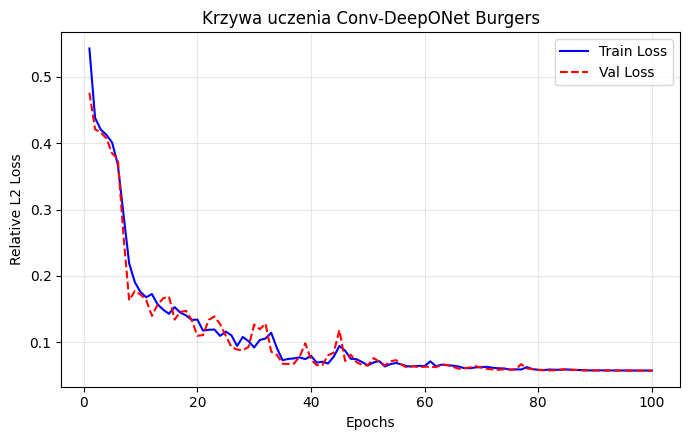

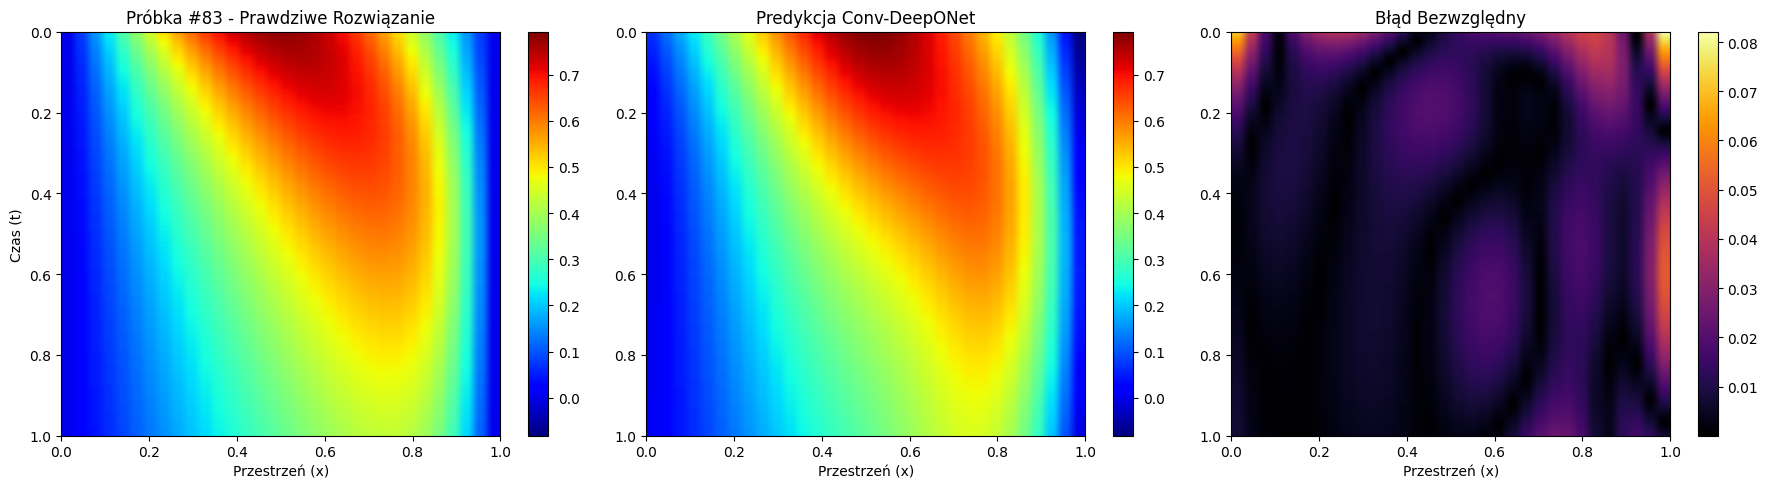

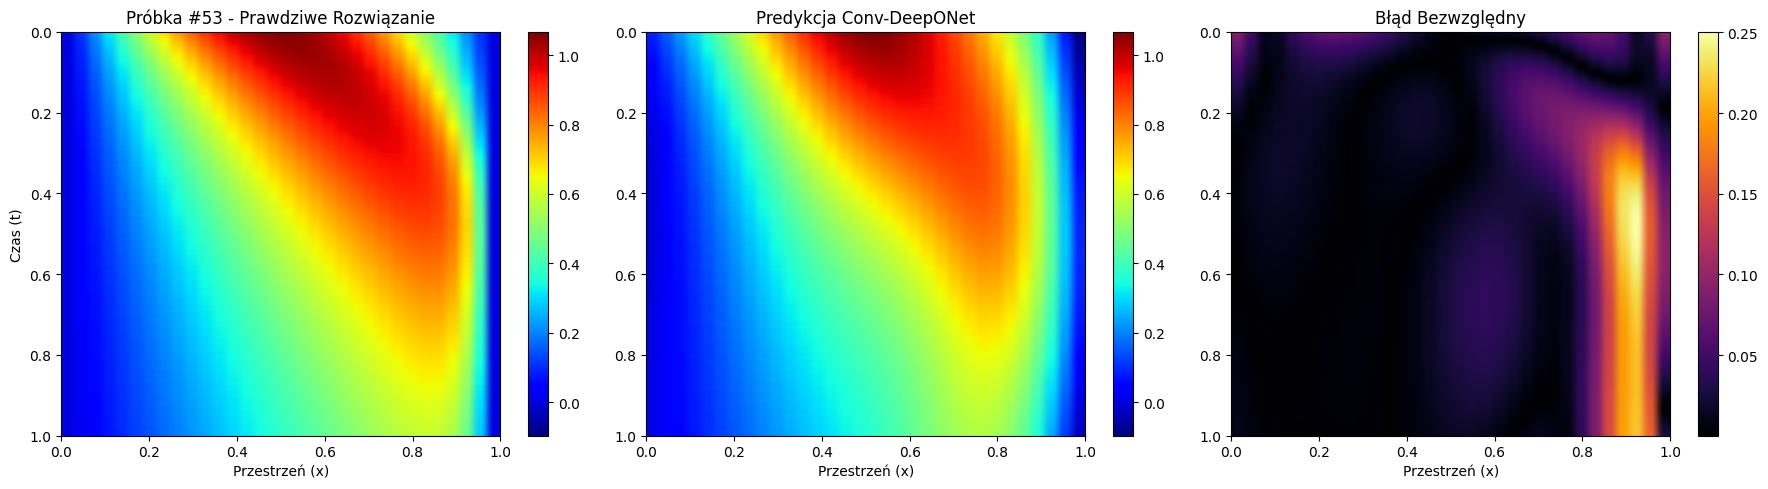

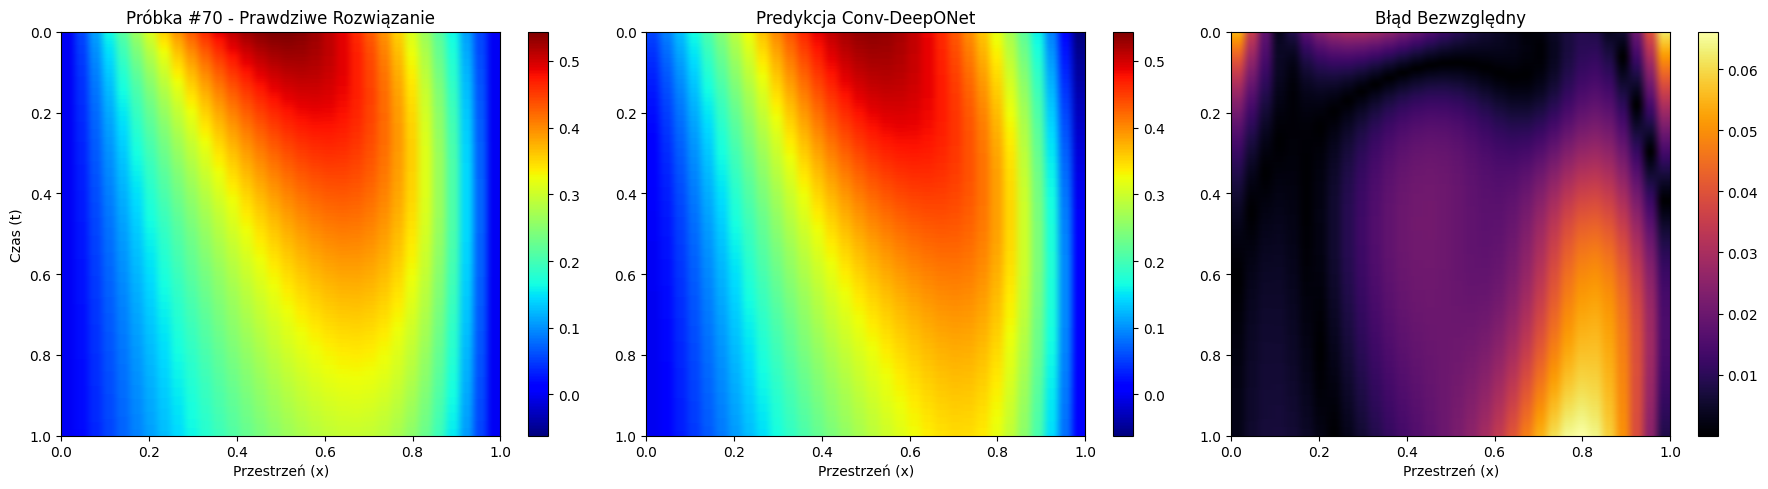

In [14]:
import matplotlib.pyplot as plt
output_dir = "deeponet_burgers_plots"
os.makedirs(output_dir, exist_ok=True)

final_don_model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for X_branch, Y_target in test_loader:
        output = final_don_model(X_branch, coords)
        all_preds.append(output.numpy())
        all_targets.append(Y_target.numpy())

all_preds = np.concatenate(all_preds, axis=0)  # Shape: (N_test, 16000)
all_targets = np.concatenate(all_targets, axis=0)  # Shape: (N_test, 16000)

# Reshape arrays back into 2D space-time topologies
Nx, Nt = 32, 500
all_preds_mesh = all_preds.reshape(-1, Nt, Nx)
all_targets_mesh = all_targets.reshape(-1, Nt, Nx)
abs_error_mesh = np.abs(all_targets_mesh - all_preds_mesh)

# Reconstruct 1D plotting coordinates
x_axis = coords[:Nx, 0].numpy()
time_axis = coords[::Nx, 1].numpy()

# --- Plot 1: Learning Curve ---
plt.figure(figsize=(7, 4.5))
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    train_loss_history,
    label="Train Loss",
    color="blue",
)
plt.plot(
    range(1, FINAL_EPOCHS + 1),
    val_loss_history,
    label="Val Loss",
    color="red",
    linestyle="--",
)
plt.xlabel("Epochs")
plt.ylabel("Relative L2 Loss")
plt.title("Krzywa uczenia Conv-DeepONet Burgers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "loss_history_DeepONet.png"), dpi=300)
plt.show()

# --- Plot 2: Random Target Sample Contour Matrices ---
np.random.seed(42)
random_indices = np.random.choice(len(all_preds_mesh), size=3, replace=False)

for sample_idx in random_indices:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    vmin = min(
        all_targets_mesh[sample_idx].min(), all_preds_mesh[sample_idx].min()
    )
    vmax = max(
        all_targets_mesh[sample_idx].max(), all_preds_mesh[sample_idx].max()
    )

    im0 = axes[0].imshow(
        all_targets_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[0].set_title(f"Próbka #{sample_idx} - Prawdziwe Rozwiązanie")
    axes[0].set_ylabel("Czas (t)")
    axes[0].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im0, ax=axes[0])

    im1 = axes[1].imshow(
        all_preds_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="jet",
        vmin=vmin,
        vmax=vmax,
    )
    axes[1].set_title("Predykcja Conv-DeepONet")
    axes[1].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im1, ax=axes[1])

    im2 = axes[2].imshow(
        abs_error_mesh[sample_idx],
        extent=[x_axis[0], x_axis[-1], time_axis[-1], time_axis[0]],
        aspect="auto",
        cmap="inferno",
    )
    axes[2].set_title("Błąd Bezwzględny")
    axes[2].set_xlabel("Przestrzeń (x)")
    fig.colorbar(im2, ax=axes[2])

    plt.tight_layout()
    plt.savefig(
        os.path.join(output_dir, f"sample_{sample_idx}_deeponet_analysis.png"),
        dpi=300,
    )
    plt.show()

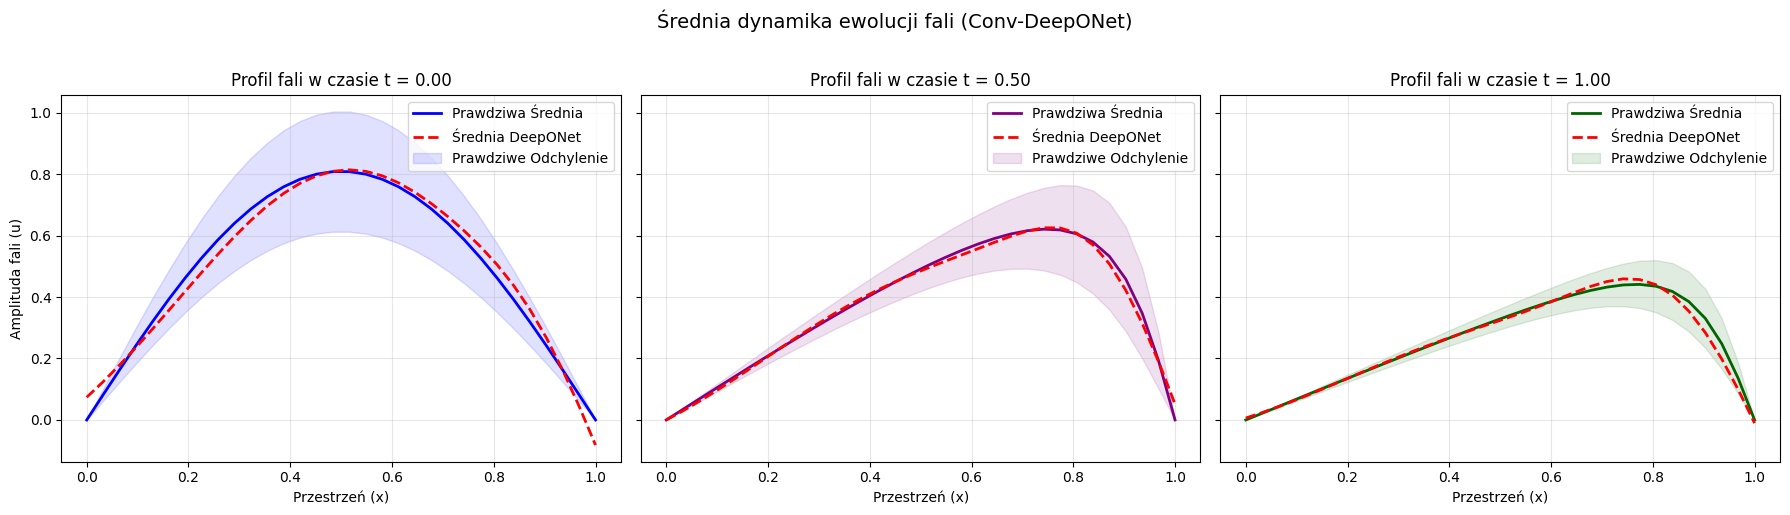

In [15]:
# Compute means and standard deviations across all validation profiles
# Shape of arrays: [Samples, Nt, Nx]
mean_target = all_targets_mesh.mean(axis=0)  # Shape: [Nt, Nx]
mean_pred = all_preds_mesh.mean(axis=0)  # Shape: [Nt, Nx]
std_target = all_targets_mesh.std(axis=0)  # Shape: [Nt, Nx]

# Pick temporal indexes to review (Initial wave form, midpoint, final dissipation state)
time_slices = [0, len(time_axis) // 2, -1]
slice_colors = ["blue", "purple", "darkgreen"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for idx, t_idx in enumerate(time_slices):
    actual_t = time_axis[t_idx]

    # Ground truth mean profile
    axes[idx].plot(
        x_axis,
        mean_target[t_idx],
        color=slice_colors[idx],
        linewidth=2,
        label="Prawdziwa Średnia",
    )

    # Conv-DeepONet mean profile prediction
    axes[idx].plot(
        x_axis,
        mean_pred[t_idx],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Średnia DeepONet",
    )

    # Fill boundaries showing physical deviation distribution across the dataset
    axes[idx].fill_between(
        x_axis,
        mean_target[t_idx] - std_target[t_idx],
        mean_target[t_idx] + std_target[t_idx],
        color=slice_colors[idx],
        alpha=0.12,
        label="Prawdziwe Odchylenie",
    )

    axes[idx].set_title(f"Profil fali w czasie t = {actual_t:.2f}")
    axes[idx].set_xlabel("Przestrzeń (x)")

    if idx == 0:
        axes[idx].set_ylabel("Amplituda fali (u)")
    axes[idx].legend(loc="upper right")
    axes[idx].grid(True, alpha=0.3)

plt.suptitle(
    "Średnia dynamika ewolucji fali (Conv-DeepONet)", fontsize=14, y=1.02
)
plt.tight_layout()

# Save the statistics profile analysis sheet
plot3_path = os.path.join(output_dir, "Burgers_DeepONet_averages.png")
plt.savefig(plot3_path, dpi=300, bbox_inches="tight")
plt.show()